# Exponential from uniform

Lecture 2 (16/11) - Distributions

## Exercise

1. Generate $10^6$ values of variable $t$, uniformly distributed in $[0, \Delta t = 10^3]$.
2. Sort the list of generated values.
3. Compute the interval $\Delta t_i = t_i - t_{i-1}$ between subsequent events.
4. Plot the distribution of $\Delta t_i$ (or a histogram).
5. Fit it with an exponential. Does it work? Do you get back the input parameters?

## Solution

In [25]:
import numpy as np
import matplotlib.pyplot as plt

from iminuit import Minuit
from iminuit.cost import UnbinnedNLL

### Functions

In [20]:
def uniform(a, b, size, rng):
    """Uniform in [a, b): rescale a uniform in [0, 1)."""
    return a + (b - a) * rng.random(size)

def exp_pdf(t, lam):
    return lam * np.exp(-lam * t)

### Plots

In [21]:
# Data
N, T = 10**6, 1e3
rng = np.random.default_rng(12345)       # fixed seed, reproducible


In [ ]:
# Generate uniform random numbers
t = uniform(0, T, N, rng)

# Sort and take the differences
dt = np.diff(np.sort(t))

# Histogram
bins = np.linspace(0, 8e-3, 101)
x = 0.5 * (bins[1:] + bins[:-1])
c, _ = np.histogram(dt, bins=bins, density="true")


In [ ]:
# What I expect from the theory
lam_exp = N / T

#Fit
cost = UnbinnedNLL(dt, exp_pdf)
m = Minuit(cost, lam=lam_exp)        # starting value
m.limits["lam"] = (0, None)      # lambda must be positive
m.migrad()                       # minimization
m.hesse()                        # errors

# What I got from the fit
lam_fit, lam_err = m.values["lam"], m.errors["lam"]


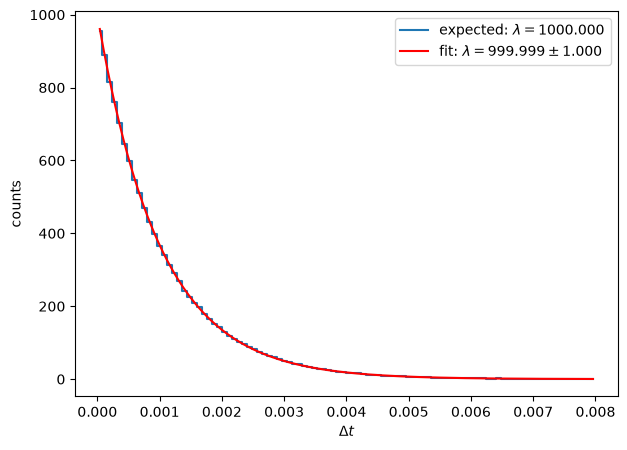

In [ ]:
x_fine = np.linspace(x.min(), x.max(), 500)    # fine grid for plotting
fit_curve = exp_pdf(x_fine, lam_fit)

fig, ax = plt.subplots(figsize=(7, 5))

ax.step(x, c, where="mid", label=rf"expected: $\lambda = {lam_exp:.3f}$")
ax.plot(x_fine, fit_curve, "r-", label=rf"fit: $\lambda = {lam_fit:.3f} \pm {lam_err:.3f}$")
ax.set_xlabel(r"$\Delta t$")
ax.set_ylabel("counts")
ax.legend()

plt.show()